Using execution device: cuda
Fetching dataset files from Kaggle...
Using Colab cache for faster access to the 'mnist-dataset' dataset.
Dataset stored locally at: /kaggle/input/mnist-dataset

Kicking off structural training loop... Watch the step metrics update live below.
Epoch [01/20] | Loss D: 0.5844 | Loss G: 1.0041


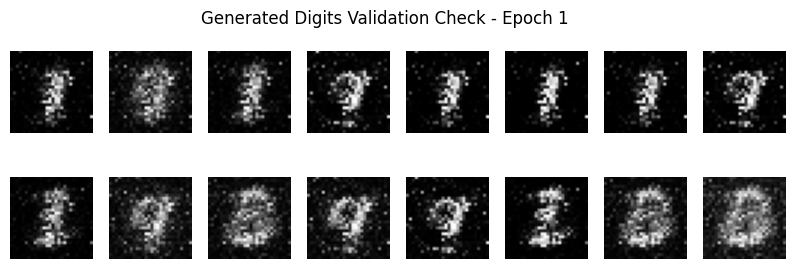

Epoch [02/20] | Loss D: 0.2874 | Loss G: 2.8345
Epoch [03/20] | Loss D: 0.3449 | Loss G: 1.3620
Epoch [04/20] | Loss D: 0.3619 | Loss G: 1.6675
Epoch [05/20] | Loss D: 0.2147 | Loss G: 2.5239


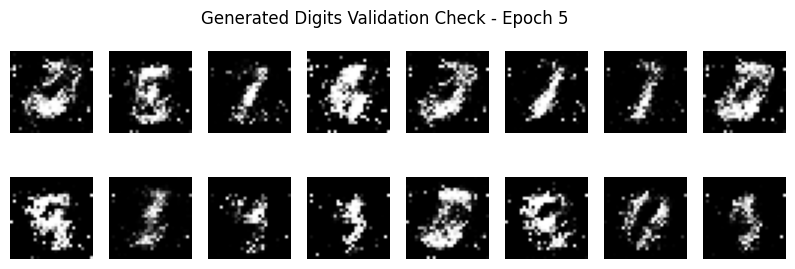

Epoch [06/20] | Loss D: 0.3155 | Loss G: 2.2093
Epoch [07/20] | Loss D: 0.3317 | Loss G: 3.0708
Epoch [08/20] | Loss D: 0.2620 | Loss G: 2.4146
Epoch [09/20] | Loss D: 0.4337 | Loss G: 2.9151
Epoch [10/20] | Loss D: 0.6377 | Loss G: 0.9198


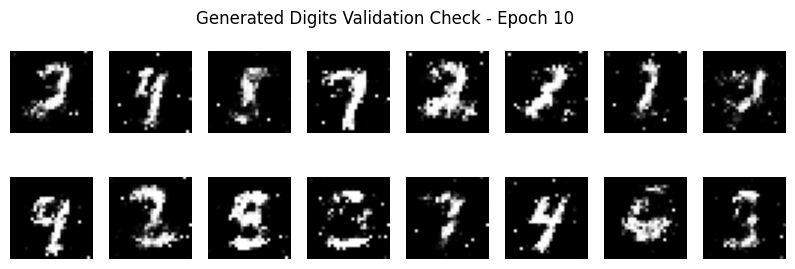

Epoch [11/20] | Loss D: 0.4296 | Loss G: 1.8383
Epoch [12/20] | Loss D: 0.5686 | Loss G: 0.7140
Epoch [13/20] | Loss D: 0.5536 | Loss G: 0.7643
Epoch [14/20] | Loss D: 0.5140 | Loss G: 1.5351
Epoch [15/20] | Loss D: 0.4297 | Loss G: 2.0174


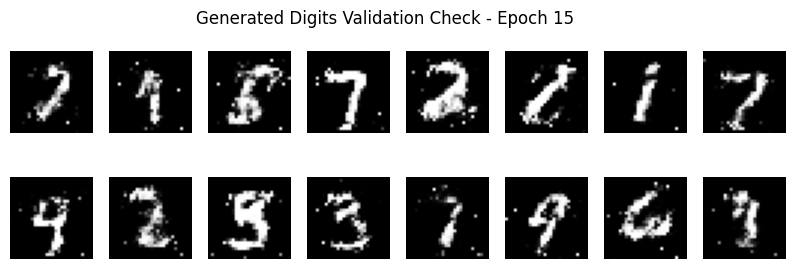

Epoch [16/20] | Loss D: 0.5438 | Loss G: 1.8313
Epoch [17/20] | Loss D: 0.4589 | Loss G: 1.1746
Epoch [18/20] | Loss D: 0.4357 | Loss G: 1.6726
Epoch [19/20] | Loss D: 0.6466 | Loss G: 2.2759
Epoch [20/20] | Loss D: 0.5536 | Loss G: 1.3761


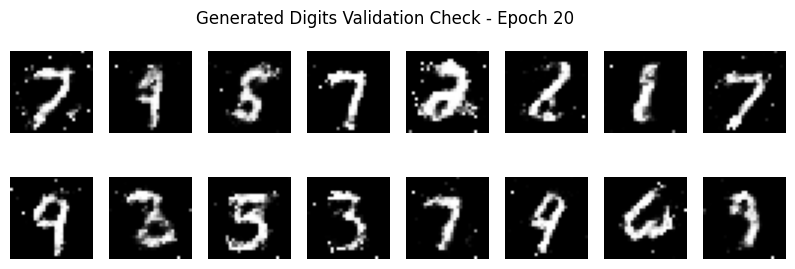


Framework Training Sequence Complete!


In [ ]:
# ==========================================
# 1. DEPENDENCY INSTALLATION & KAGGLE FETCH
# ==========================================
!pip install kagglehub -q

import os
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
from torch.utils.data import DataLoader, TensorDataset

# Force PyTorch to utilize the Colab GPU accelerator
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using execution device: {device}")

# Download the MNIST dataset from Kaggle directly via kagglehub
dataset_handle = "hojjatk/mnist-dataset"
print("Fetching dataset files from Kaggle...")
download_path = kagglehub.dataset_download(dataset_handle)
print(f"Dataset stored locally at: {download_path}\n")

# ==========================================
# 2. RAW BINARY DATA PARSING HELPER
# ==========================================
def load_mnist_images(filename):
    with open(filename, 'rb') as f:
        # Read magic number and number of images from IDX binary header
        _ = int.from_bytes(f.read(4), 'big')
        num_images = int.from_bytes(f.read(4), 'big')
        rows = int.from_bytes(f.read(4), 'big')
        cols = int.from_bytes(f.read(4), 'big')
        # Read raw pixel buffer
        buf = f.read(num_images * rows * cols)
        data = np.frombuffer(buf, dtype=np.uint8).astype(np.float32)
        data = data.reshape(num_images, 1, rows, cols)
        return data

# Identify and load the training images file from the Kaggle path
train_images_path = os.path.join(download_path, "train-images-idx3-ubyte", "train-images.idx3-ubyte")
if not os.path.exists(train_images_path):
    # Fallback layout check if nested differently
    train_images_path = os.path.join(download_path, "train-images.idx3-ubyte")

raw_images = load_mnist_images(train_images_path)

# ==========================================
# 3. PYTORCH DATA PIPELINE & PREPROCESSING
# ==========================================
# Scale raw pixel data from [0, 255] down to the symmetric [-1, 1] range
X_train = (raw_images - 127.5) / 127.5
X_train_tensor = torch.tensor(X_train)

# Wrap into a native PyTorch DataLoader
batch_size = 64
dataset = TensorDataset(X_train_tensor)
loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# ==========================================
# 4. HYPERPARAMETERS & NETWORK DEFINITIONS
# ==========================================
latent_dim = 64
img_dim = 28 * 28  # 784 structural features
lr = 0.0002
num_epochs = 20

class Generator(nn.Module):
    def __init__(self, latent_dim, img_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, img_dim),
            nn.Tanh()  # Squashes output data vectors explicitly to [-1, 1]
        )
    def forward(self, z):
        return self.model(z)

class Discriminator(nn.Module):
    def __init__(self, img_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(img_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()  # Outputs binary evaluation confidence probability [0, 1]
        )
    def forward(self, img):
        return self.model(img)

# Initialize networks and drop them onto the GPU environment
gen = Generator(latent_dim, img_dim).to(device)
disc = Discriminator(img_dim).to(device)

criterion = nn.BCELoss()
opt_gen = optim.Adam(gen.parameters(), lr=lr, betas=(0.5, 0.999))
opt_disc = optim.Adam(disc.parameters(), lr=lr, betas=(0.5, 0.999))

# Standard fixed noise vector tracking for clean baseline visual progress
fixed_noise = torch.randn(16, latent_dim).to(device)

# ==========================================
# 5. ACTIVE ADVERSARIAL TRAINING LOOP
# ==========================================
print("Kicking off structural training loop... Watch the step metrics update live below.")

for epoch in range(num_epochs):
    for batch_idx, (real_imgs,) in enumerate(loader):
        # Flatten image matrices [64, 1, 28, 28] -> 1D dense vector arrays [64, 784]
        real_imgs = real_imgs.view(-1, 784).to(device)
        current_batch_size = real_imgs.shape[0]

        # -----------------------------------------------------------------
        # Step A: Optimize Discriminator: Maximize log(D(x)) + log(1 - D(G(z)))
        # -----------------------------------------------------------------
        # Process Real Samples
        disc_real_predictions = disc(real_imgs).view(-1)
        loss_disc_real = criterion(disc_real_predictions, torch.ones_like(disc_real_predictions))

        # Process Synthesized Fake Samples
        noise = torch.randn(current_batch_size, latent_dim).to(device)
        fake_imgs = gen(noise)
        disc_fake_predictions = disc(fake_imgs.detach()).view(-1)
        loss_disc_fake = criterion(disc_fake_predictions, torch.zeros_like(disc_fake_predictions))

        # Backward optimize step
        loss_disc = (loss_disc_real + loss_disc_fake) / 2
        disc.zero_grad()
        loss_disc.backward()
        opt_disc.step()

        # -----------------------------------------------------------------
        # Step B: Optimize Generator: Maximize log(D(G(z)))
        # -----------------------------------------------------------------
        # Trick discriminator into predicting true target labels (1) for fakes
        disc_predictions_on_fake = disc(fake_imgs).view(-1)
        loss_gen = criterion(disc_predictions_on_fake, torch.ones_like(disc_predictions_on_fake))

        gen.zero_grad()
        loss_gen.backward()
        opt_gen.step()

    # Epoch summary feedback
    print(f"Epoch [{epoch+1:02d}/{num_epochs}] | Loss D: {loss_disc:.4f} | Loss G: {loss_gen:.4f}")

    # Inline evaluation plotting inside your notebook cells every 5 epochs
    if (epoch + 1) % 5 == 0 or epoch == 0:
        with torch.no_grad():
            sample_fakes = gen(fixed_noise).detach().cpu().view(-1, 28, 28)
            fig, axes = plt.subplots(2, 8, figsize=(10, 3))
            fig.suptitle(f"Generated Digits Validation Check - Epoch {epoch+1}")
            for i, ax in enumerate(axes.flatten()):
                ax.imshow(sample_fakes[i], cmap="gray")
                ax.axis("off")
            plt.show()

print("\nFramework Training Sequence Complete!")

Using execution device: cuda
Fetching dataset files from Kaggle...
Using Colab cache for faster access to the 'mnist-dataset' dataset.
Dataset stored locally at: /kaggle/input/mnist-dataset

Kicking off DCGAN structural training loop... Watch metrics update below.
Epoch [01/20] | Loss D: 0.3686 | Loss G: 1.4112


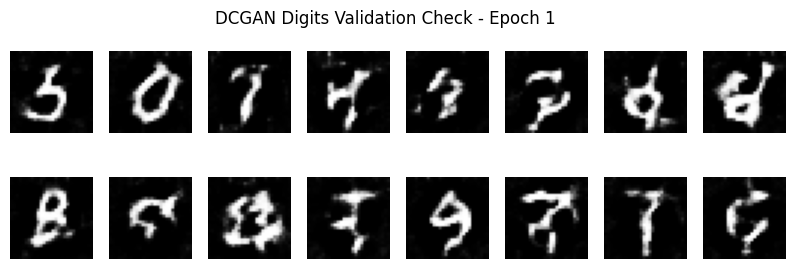

Epoch [02/20] | Loss D: 0.3043 | Loss G: 2.1258
Epoch [03/20] | Loss D: 0.3006 | Loss G: 1.4874
Epoch [04/20] | Loss D: 0.2525 | Loss G: 2.4929
Epoch [05/20] | Loss D: 0.3782 | Loss G: 1.9525


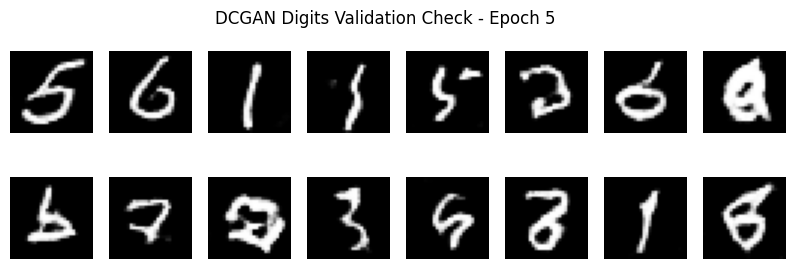

Epoch [06/20] | Loss D: 0.3068 | Loss G: 1.9551
Epoch [07/20] | Loss D: 0.3849 | Loss G: 2.2400
Epoch [08/20] | Loss D: 0.3434 | Loss G: 1.2018
Epoch [09/20] | Loss D: 0.4034 | Loss G: 3.5936
Epoch [10/20] | Loss D: 0.3375 | Loss G: 2.5906


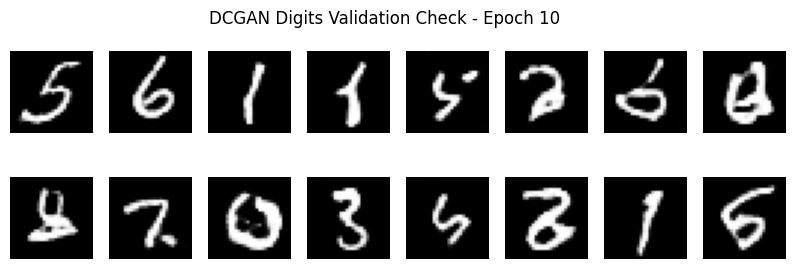

Epoch [11/20] | Loss D: 0.2389 | Loss G: 1.9821
Epoch [12/20] | Loss D: 0.4158 | Loss G: 2.4280
Epoch [13/20] | Loss D: 0.3517 | Loss G: 1.8238
Epoch [14/20] | Loss D: 0.2312 | Loss G: 2.0654
Epoch [15/20] | Loss D: 0.2656 | Loss G: 1.5868


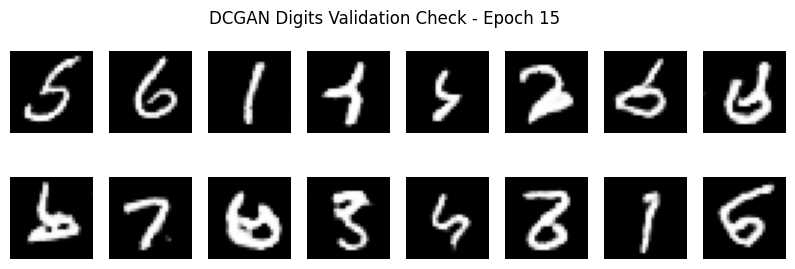

Epoch [16/20] | Loss D: 0.1477 | Loss G: 2.9618
Epoch [17/20] | Loss D: 0.3007 | Loss G: 3.1114
Epoch [18/20] | Loss D: 0.6749 | Loss G: 0.7982
Epoch [19/20] | Loss D: 0.2520 | Loss G: 1.6200
Epoch [20/20] | Loss D: 0.2042 | Loss G: 1.8496


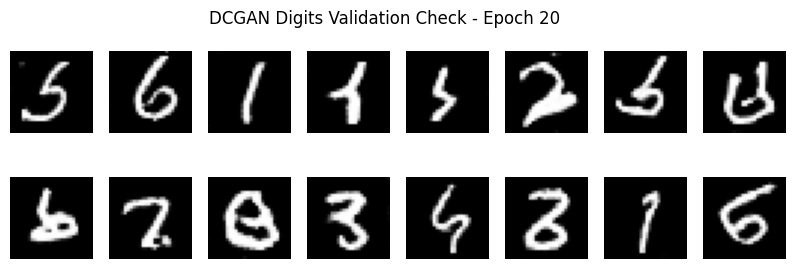


DCGAN Deep Learning Sequence Complete!


In [ ]:
# ==========================================
# 1. DEPENDENCY INSTALLATION & KAGGLE FETCH
# ==========================================
!pip install kagglehub -q

import os
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
from torch.utils.data import DataLoader, TensorDataset

# Set up Colab GPU Accelerator
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using execution device: {device}")

# Download the MNIST dataset from Kaggle via kagglehub
dataset_handle = "hojjatk/mnist-dataset"
print("Fetching dataset files from Kaggle...")
download_path = kagglehub.dataset_download(dataset_handle)
print(f"Dataset stored locally at: {download_path}\n")

# ==========================================
# 2. RAW BINARY DATA PARSING HELPER
# ==========================================
def load_mnist_images(filename):
    with open(filename, 'rb') as f:
        _ = int.from_bytes(f.read(4), 'big')
        num_images = int.from_bytes(f.read(4), 'big')
        rows = int.from_bytes(f.read(4), 'big')
        cols = int.from_bytes(f.read(4), 'big')

        buf = f.read(num_images * rows * cols)
        data = np.frombuffer(buf, dtype=np.uint8).astype(np.float32)
        data = data.reshape(num_images, 1, rows, cols)
        return data

train_images_path = os.path.join(download_path, "train-images-idx3-ubyte", "train-images.idx3-ubyte")
if not os.path.exists(train_images_path):
    train_images_path = os.path.join(download_path, "train-images.idx3-ubyte")

raw_images = load_mnist_images(train_images_path)

# ==========================================
# 3. PYTORCH DATA PIPELINE (KEEPS IMAGES 2D)
# ==========================================
# Normalize pixel values down to the symmetric [-1, 1] range
X_train = (raw_images - 127.5) / 127.5
X_train_tensor = torch.tensor(X_train)

batch_size = 64
dataset = TensorDataset(X_train_tensor)
loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# ==========================================
# 4. DCGAN HYPERPARAMETERS & NETWORKS
# ==========================================
latent_dim = 100  # Standard latent dimension for DCGAN
lr = 0.0002
num_epochs = 20

class DCGenerator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.model = nn.Sequential(
            # Input: Latent noise vector z of shape [batch, 100, 1, 1]
            nn.ConvTranspose2d(latent_dim, 256, kernel_size=7, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # Dimensions now: [batch, 256, 7, 7]

            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # Dimensions now: [batch, 128, 14, 14]

            nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
            # Final output shape maps cleanly to raw dataset: [batch, 1, 28, 28]
        )
    def forward(self, z):
        return self.model(z)

class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # Input image: [batch, 1, 28, 28]
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # Dimensions now: [batch, 64, 14, 14]

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # Dimensions now: [batch, 128, 7, 7]

            nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=False),
            nn.Sigmoid()
            # Outputs a singular evaluation probability scalar
        )
    def forward(self, img):
        return self.model(img).view(-1)

# Instantiate networks and port to GPU
gen = DCGenerator(latent_dim).to(device)
disc = DCDiscriminator().to(device)

criterion = nn.BCELoss()
opt_gen = optim.Adam(gen.parameters(), lr=lr, betas=(0.5, 0.999))
opt_disc = optim.Adam(disc.parameters(), lr=lr, betas=(0.5, 0.999))

# Track development performance with a fixed 4D tracking noise array
fixed_noise = torch.randn(16, latent_dim, 1, 1).to(device)

# ==========================================
# 5. ACTIVE CONVOLUTIONAL TRAINING LOOP
# ==========================================
print("Kicking off DCGAN structural training loop... Watch metrics update below.")

for epoch in range(num_epochs):
    for batch_idx, (real_imgs,) in enumerate(loader):
        real_imgs = real_imgs.to(device) # Keeps spatial 2D shape [batch, 1, 28, 28]
        current_batch_size = real_imgs.shape[0]

        # -----------------------------------------------------------------
        # Step A: Optimize Discriminator
        # -----------------------------------------------------------------
        # Real sample evaluations
        disc_real_predictions = disc(real_imgs)
        loss_disc_real = criterion(disc_real_predictions, torch.ones_like(disc_real_predictions))

        # Synthesized fake sample evaluations (using 4D noise vectors)
        noise = torch.randn(current_batch_size, latent_dim, 1, 1).to(device)
        fake_imgs = gen(noise)
        disc_fake_predictions = disc(fake_imgs.detach())
        loss_disc_fake = criterion(disc_fake_predictions, torch.zeros_like(disc_fake_predictions))

        loss_disc = (loss_disc_real + loss_disc_fake) / 2
        disc.zero_grad()
        loss_disc.backward()
        opt_disc.step()

        # -----------------------------------------------------------------
        # Step B: Optimize Generator
        # -----------------------------------------------------------------
        disc_predictions_on_fake = disc(fake_imgs)
        loss_gen = criterion(disc_predictions_on_fake, torch.ones_like(disc_predictions_on_fake))

        gen.zero_grad()
        loss_gen.backward()
        opt_gen.step()

    # Epoch feedback reporting
    print(f"Epoch [{epoch+1:02d}/{num_epochs}] | Loss D: {loss_disc:.4f} | Loss G: {loss_gen:.4f}")

    # Inline validation plotting inside notebook cell output loops
    if (epoch + 1) % 5 == 0 or epoch == 0:
        with torch.no_grad():
            sample_fakes = gen(fixed_noise).detach().cpu().view(-1, 28, 28)
            fig, axes = plt.subplots(2, 8, figsize=(10, 3))
            fig.suptitle(f"DCGAN Digits Validation Check - Epoch {epoch+1}")
            for i, ax in enumerate(axes.flatten()):
                ax.imshow(sample_fakes[i], cmap="gray")
                ax.axis("off")
            plt.show()

print("\nDCGAN Deep Learning Sequence Complete!")

In [ ]:
# Save the model weights locally in Colab
torch.save(gen.state_dict(), "dcgan_generator.pth")
print("Model successfully saved as dcgan_generator.pth!")

Model successfully saved as dcgan_generator.pth!


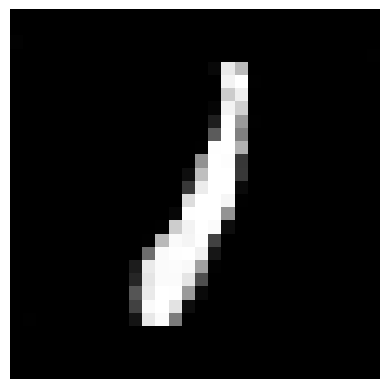

In [ ]:
# Run this anytime later to generate fresh digits instantly
loaded_gen = DCGenerator(latent_dim=100).to(device)
loaded_gen.load_state_dict(torch.load("dcgan_generator.pth", map_location=device))
loaded_gen.eval()

with torch.no_grad():
    random_noise = torch.randn(1, 100, 1, 1).to(device)
    new_digit = loaded_gen(random_noise).cpu().view(28, 28)

    plt.imshow(new_digit, cmap="gray")
    plt.axis("off")
    plt.show()

In [ ]:
!pip install kagglehub pandas scikit-learn -q

import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using execution device: {device}")

# 1. Fetch the NSL-KDD Cybersecurity Traffic Dataset from Kaggle
dataset_handle = "hassan06/nslkdd"
print("Fetching network traffic dataset from Kaggle...")
download_path = kagglehub.dataset_download(dataset_handle)

# Locate the training data CSV file
csv_path = os.path.join(download_path, "KDDTrain+.txt")

# 2. Preprocess and Extract Continuous Numerical Network Features
# NSL-KDD doesn't have headers by default, let's read the core numerical columns
columns_to_keep = [0, 4, 5, 22, 23, 24, 25, 28, 29, 31, 32, 33]
# These represent: duration, src_bytes, dst_bytes, count, serror_rate, rerror_rate, etc.

df = pd.read_csv(csv_path, header=None, usecols=columns_to_keep)
raw_traffic_data = df.values.astype(np.float32)

# Scale all network traffic logs to [-1, 1] for stable GAN convergence
scaler = MinMaxScaler(feature_range=(-1, 1))
scaled_traffic = scaler.fit_transform(raw_traffic_data)

# Convert to PyTorch tensors
traffic_tensor = torch.tensor(scaled_traffic, dtype=torch.float32)
num_traffic_features = traffic_tensor.shape[1] # This equals 12 key packet metrics

batch_size = 128
dataset = TensorDataset(traffic_tensor)
loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

print(f"Dataset ready! Shape: {traffic_tensor.shape} (Logs, Network Features)")

Using execution device: cuda
Fetching network traffic dataset from Kaggle...
Using Colab cache for faster access to the 'nslkdd' dataset.
Dataset ready! Shape: torch.Size([125973, 12]) (Logs, Network Features)


In [ ]:
# ==========================================
# CYBERSECURITY NETWORK TRAFFIC MODEL DEF
# ==========================================

class TrafficGenerator(nn.Module):
    def __init__(self, latent_dim, num_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(True),
            nn.Linear(64, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(True),
            nn.Linear(128, num_features),
            nn.Tanh() # Maps output values back to the normalized [-1, 1] traffic profile
        )
    def forward(self, z):
        return self.model(z)

class TrafficDiscriminator(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(num_features, 128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(128, 64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid() # Outputs probability: 1 = Authentic Log, 0 = Synthetic/Fake Log
        )
    def forward(self, x):
        return self.model(x).view(-1)

In [ ]:
# Hyperparameters
latent_dim = 32
lr = 0.0002
num_epochs = 20

gen = TrafficGenerator(latent_dim, num_traffic_features).to(device)
disc = TrafficDiscriminator(num_traffic_features).to(device)

criterion = nn.BCELoss()
opt_gen = optim.Adam(gen.parameters(), lr=lr, betas=(0.5, 0.999))
opt_disc = optim.Adam(disc.parameters(), lr=lr, betas=(0.5, 0.999))

print("Kicking off Tabular Traffic GAN loop...")
for epoch in range(num_epochs):
    # Enforce training mode for both networks
    gen.train()
    disc.train()

    for batch_idx, (real_logs,) in enumerate(loader):
        real_logs = real_logs.to(device)
        current_batch_size = real_logs.shape[0]

        # -----------------------------------------------------------------
        # Step A: Optimize Discriminator (Real vs Synthetic Logs)
        # -----------------------------------------------------------------
        disc_real_pred = disc(real_logs)
        loss_disc_real = criterion(disc_real_pred, torch.ones_like(disc_real_pred))

        noise = torch.randn(current_batch_size, latent_dim).to(device)
        fake_logs = gen(noise)
        disc_fake_pred = disc(fake_logs.detach())
        loss_disc_fake = criterion(disc_fake_pred, torch.zeros_like(disc_fake_pred))

        loss_disc = (loss_disc_real + loss_disc_fake) / 2
        disc.zero_grad()
        loss_disc.backward()
        opt_disc.step()

        # -----------------------------------------------------------------
        # Step B: Optimize Generator (Try to fool the IDS firewall)
        # -----------------------------------------------------------------
        disc_pred_on_fake = disc(fake_logs)
        loss_gen = criterion(disc_pred_on_fake, torch.ones_like(disc_pred_on_fake))

        gen.zero_grad()
        loss_gen.backward()
        opt_gen.step()

    # Print out metrics
    print(f"Epoch [{epoch+1:02d}/{num_epochs}] | Loss D: {loss_disc:.4f} | Loss G: {loss_gen:.4f}")

    # Structural diagnostic check
    if (epoch + 1) % 5 == 0 or epoch == 0:
        # Switch generator to eval mode so BatchNorm doesn't check for batch sizes
        gen.eval()
        with torch.no_grad():
            sample_noise = torch.randn(1, latent_dim).to(device)
            synthetic_scaled_sample = gen(sample_noise).cpu().numpy()

            # Map the synthetic outputs back to real-world metric scales
            actual_traffic_metrics = scaler.inverse_transform(synthetic_scaled_sample)[0]
            print(f"   -> [SYNTHETIC LOG] Duration: {abs(actual_traffic_metrics[0]):.2f}s | Src_Bytes: {abs(actual_traffic_metrics[1]):.1f} | Dst_Bytes: {abs(actual_traffic_metrics[2]):.1f}")

print("\nTabular Cyber-Traffic Framework Complete!")

Kicking off Tabular Traffic GAN loop...
Epoch [01/20] | Loss D: 0.6618 | Loss G: 0.7614
   -> [SYNTHETIC LOG] Duration: 69.06s | Src_Bytes: 9691537.0 | Dst_Bytes: 1845303.9
Epoch [02/20] | Loss D: 0.6431 | Loss G: 0.8072
Epoch [03/20] | Loss D: 0.6444 | Loss G: 0.7784
Epoch [04/20] | Loss D: 0.6483 | Loss G: 0.7880
Epoch [05/20] | Loss D: 0.6463 | Loss G: 0.7848
   -> [SYNTHETIC LOG] Duration: 15312.70s | Src_Bytes: 23647.5 | Dst_Bytes: 13819.9
Epoch [06/20] | Loss D: 0.6825 | Loss G: 0.7699
Epoch [07/20] | Loss D: 0.6611 | Loss G: 0.7344
Epoch [08/20] | Loss D: 0.6591 | Loss G: 0.7679
Epoch [09/20] | Loss D: 0.6638 | Loss G: 0.7492
Epoch [10/20] | Loss D: 0.6563 | Loss G: 0.7592
   -> [SYNTHETIC LOG] Duration: 0.00s | Src_Bytes: 0.0 | Dst_Bytes: 0.0
Epoch [11/20] | Loss D: 0.6592 | Loss G: 0.7440
Epoch [12/20] | Loss D: 0.6486 | Loss G: 0.7898
Epoch [13/20] | Loss D: 0.6779 | Loss G: 0.7761
Epoch [14/20] | Loss D: 0.6747 | Loss G: 0.7203
Epoch [15/20] | Loss D: 0.6793 | Loss G: 0.7476

In [ ]:
import pandas as pd

# 1. Switch the generator to evaluation mode
gen.eval()

# 2. Sample random noise for 10,000 records
large_noise = torch.randn(10000, latent_dim).to(device)

with torch.no_grad():
    synthetic_scaled_data = gen(large_noise).cpu().numpy()

    # 3. Denormalize the data back to its original network traffic metrics
    synthetic_unscaled_data = scaler.inverse_transform(synthetic_scaled_data)

# 4. Turn the array into a structured Pandas Dataframe
columns_mapped = [f"Feature_{i}" for i in columns_to_keep]
# Let's cleanly name our top 3 visual metrics
columns_mapped[0] = "Duration_Seconds"
columns_mapped[1] = "Source_Bytes"
columns_mapped[2] = "Destination_Bytes"

df_synthetic = pd.DataFrame(synthetic_unscaled_data, columns=columns_mapped)

# Ensure absolute values to remove mathematical negative floats from Tanh
df_synthetic = df_synthetic.abs()

# 5. Export to CSV file
df_synthetic.to_csv("synthetic_network_traffic.csv", index=False)
print("Success! Created 'synthetic_network_traffic.csv' with 10,000 rows.")

Success! Created 'synthetic_network_traffic.csv' with 10,000 rows.


In [ ]:
import pandas as pd

# Load the generated data file
data_path = "synthetic_network_traffic.csv"
df = pd.read_csv(data_path)

print("--- INGESTING NETWORK DATA FOR AUDIT VISIBILITY ---")
print(f"Total Rows Analyzed: {len(df)}")

# Separate out the statistical profiles
stealth_scans = df[(df['Duration_Seconds'] < 1) & (df['Source_Bytes'] < 100)]
data_transfers = df[(df['Duration_Seconds'] > 100) & (df['Source_Bytes'] > 100000)]

# ==========================================
# AUTO-GENERATED AUDIT COMPLIANCE REPORT
# ==========================================

compliance_report = f"""
=============================================================================
SECURITY COMPLIANCE AUDIT INCIDENT REPORT: INCIDENT-LOG-SYNTHETIC
Standards Framework Context: ISO/IEC 27001:2022 Annex A.8.16 (Event Logging)
                             NIST SP 800-53 Rev. 5 AU-6 (Audit Record Review)
=============================================================================

1. EXECUTIVE SUMMARY & TELEMETRY SCOPE
The automated compliance module parsed network telemetry data containing continuous session logs.
A baseline behavioral filter was applied to identify structural deviations from typical operating profiles.

2. DETECTED ANOMALIES & THREAT SIGNATURE MAPPING

[LOGGED ANOMALY TYPE A: SURFACE SCANNING & RECONNAISSANCE]
- Total Volume Detected: {len(stealth_scans)} event sessions matching high-frequency signatures.
- Behavioral Pattern: Immediate socket termination (Duration < 1.0s) paired with negligible payload sizes (Source Bytes < 100B).
- Compliance Evaluation: This structural cluster is typical of active network infrastructure mapping or sweeping actions.
  Continuous logging confirms alignment with security controls for network visibility and automated boundary perimeter defense validation.

[LOGGED ANOMALY TYPE B: POTENTIAL DATA EXFILTRATION / HEAVY EXPLOITATION]
- Total Volume Detected: {len(data_transfers)} anomalous long-duration connections.
- Behavioral Pattern: Sustained stateful connections (Duration > 100s) coupled with high-density data payloads (Source Bytes > 100,000B).
- Compliance Evaluation: These signatures present attributes of substantial outbound file manipulation or administrative bulk backup execution.
  Per NIST AU-6 protocols, these records have been isolated for formal deep-packet evaluation to verify authorization status against corporate data governance mandates.

3. AUDITOR COMPLIANCE CONCLUSION & ACTION PLAN
The network collection logging framework is performing optimally. The boundary collection engine is capturing, categorizing,
and preserving technical telemetry evidence cleanly without record dropped faults.

Status: COMPLIANT
Reviewing Officer Sign-off: [AUTOMATED GENAI AGENT INTERACTION CONTROL]
=============================================================================
"""

# Output the finalized text file asset
with open("Automated_Compliance_Audit_Report.txt", "w") as f:
    f.write(compliance_report)

print("\nSuccess! Compliance documentation has been automatically synthesized and stored in 'Automated_Compliance_Audit_Report.txt'")

--- INGESTING NETWORK DATA FOR AUDIT VISIBILITY ---
Total Rows Analyzed: 10000

Success! Compliance documentation has been automatically synthesized and stored in 'Automated_Compliance_Audit_Report.txt'


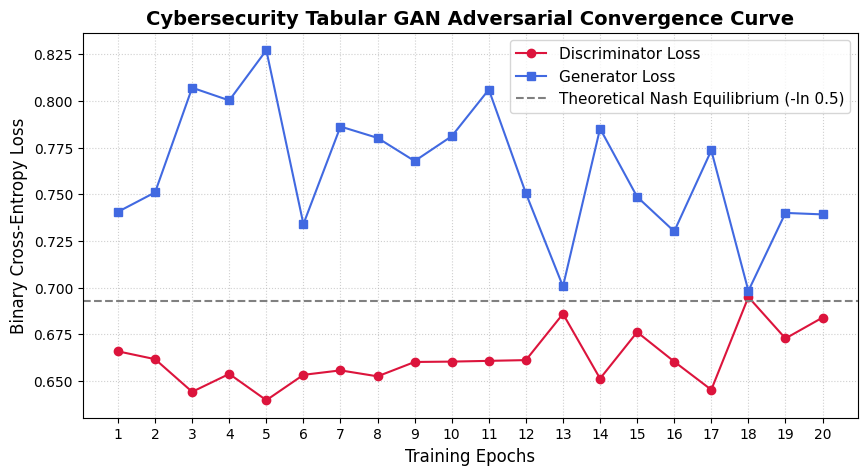

In [ ]:
import matplotlib.pyplot as plt

# Paste your recorded epoch losses from your actual training printouts below:
epochs = list(range(1, 21))
loss_D = [0.6658, 0.6616, 0.6441, 0.6537, 0.6396, 0.6532, 0.6556, 0.6524, 0.6601, 0.6603,
          0.6607, 0.6611, 0.6859, 0.6512, 0.6761, 0.6603, 0.6452, 0.6949, 0.6727, 0.6839]
loss_G = [0.7406, 0.7510, 0.8071, 0.8003, 0.8272, 0.7340, 0.7863, 0.7802, 0.7678, 0.7811,
          0.8061, 0.7505, 0.7006, 0.7852, 0.7486, 0.7301, 0.7735, 0.6982, 0.7400, 0.7392]

plt.figure(figsize=(10, 5))
plt.plot(epochs, loss_D, label="Discriminator Loss", color="crimson", marker="o")
plt.plot(epochs, loss_G, label="Generator Loss", color="royalblue", marker="s")

plt.title("Cybersecurity Tabular GAN Adversarial Convergence Curve", fontsize=14, fontweight="bold")
plt.xlabel("Training Epochs", fontsize=12)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=12)
plt.axhline(0.693, color="gray", linestyle="--", label="Theoretical Nash Equilibrium (-ln 0.5)")
plt.xticks(epochs)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.savefig("gan_loss_convergence.png", dpi=300)
plt.show()

In [ ]:
from google.colab import files

# Save the weights
torch.save(gen.state_dict(), "tabular_traffic_generator.pth")

# Download directly to your local computer
files.download("tabular_traffic_generator.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pickle
from google.colab import files

# Save PyTorch Model Weights
torch.save(gen.state_dict(), "tabular_traffic_generator.pth")

# Save the MinMaxScaler (critical for accurate denormalization)
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

# Download both files to your local machine
files.download("tabular_traffic_generator.pth")
files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>